# ЛР№2 - Построение и оценка регрессионной модели

**Дисциплина:** Введение в искусственный интеллект
**Студент:** Силкин Илья Алексеевич, группа 22206
**Данные:** `assets/data/Fish.csv` (159 × 7)
**Seed:** `RANDOM_STATE = 42`
**Цель:** построить воспроизводимую
модель массы рыбы, сравнить линейный и нелинейный подходы и зафиксировать экс-
перименты.

In [42]:
import os
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

# --- Корень проекта = текущая директория Jupyter ---
PROJECT_ROOT = Path.cwd().resolve()
os.chdir(PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)

# --- Проверка: где лежит Fish.csv ---
DATA_PATH = PROJECT_ROOT / "assets" / "data" / "Fish.csv"
print("Fish.csv exists:", DATA_PATH.exists())
print("Fish.csv path:", DATA_PATH)

# --- Таблица E0–E4 ---
metrics = json.loads((PROJECT_ROOT / "models" / "best_model_metrics.json").read_text())
best_id = metrics["best_experiment"]

rows = []
for k in ["E0", "E1", "E2", "E3", "E4"]:
    r = metrics[k]
    rows.append({
        "ID": k,
        "Name": r["name"],
        "Test MSE": round(r["test"]["mse"], 2),
        "Test RMSE": round(r["test"]["rmse"], 2),
        "Test MAE": round(r["test"]["mae"], 2),
        "Test R²": round(r["test"]["r2"], 4),
    })

print(f"\nЛучшая модель по CV MSE: {best_id}")
display(pd.DataFrame(rows))

Project root: C:\Users\User\Desktop\fish_weight_prediction_machine_learning-master
Fish.csv exists: True
Fish.csv path: C:\Users\User\Desktop\fish_weight_prediction_machine_learning-master\assets\data\Fish.csv

Лучшая модель по CV MSE: E1


,ID,Name,Test MSE,Test RMSE,Test MAE,Test R²
0,E0,naive_baseline_mean,103849.18,322.26,287.07,-0.0166
1,E1,linear_regression_log_target,1593.63,39.92,24.98,0.9844
2,E2,ridge_regression_cv,5324.41,72.97,53.64,0.9479
3,E3,random_forest,4148.50,64.41,40.98,0.9594
4,E4,linear_regression_no_species,6426.56,80.17,57.12,0.9371


In [43]:
test_metrics = metrics[best_id]["test"]

try:
    boot = json.loads(Path("reports/bootstrap_ci.json").read_text())
    boot_msg = (
        f"Bootstrap 95% CI (N={boot['n_iterations']}):\n"
        f"  RMSE: [{boot['rmse_ci_95'][0]:.2f}; {boot['rmse_ci_95'][1]:.2f}] г\n"
        f"  R²:   [{boot['r2_ci_95'][0]:.4f}; {boot['r2_ci_95'][1]:.4f}]"
    )
except FileNotFoundError:
    boot_msg = "Bootstrap CI не найден (запустите python -m src.bootstrap_ci)"

print(f"=== {best_id}: {metrics[best_id]['name']} ===")
print(f"  MSE:  {test_metrics['mse']:.2f}")
print(f"  RMSE: {test_metrics['rmse']:.2f} г")
print(f"  MAE:  {test_metrics['mae']:.2f} г")
print(f"  R²:   {test_metrics['r2']:.4f}")
print()
print(boot_msg)

=== E1: linear_regression_log_target ===
  MSE:  1593.63
  RMSE: 39.92 г
  MAE:  24.98 г
  R²:   0.9844

Bootstrap 95% CI (N=1000):
  RMSE: [21.45; 59.33] г
  R²:   [0.9573; 0.9952]


## Анализ ошибок

In [44]:
print("=== Топ-5 ошибок ===")
display(pd.read_csv("reports/error_top5.csv"))

print("\n=== MAE по видам ===")
display(pd.read_csv("reports/error_mae_by_species.csv"))

print("\n=== MAE по диапазонам массы ===")
display(pd.read_csv("reports/error_mae_by_weight_range.csv"))

neg = pd.read_csv("reports/error_non_positive_predictions.csv")
print(f"\nОтрицательных/нулевых прогнозов: {len(neg)}")

=== Топ-5 ошибок ===


,Species,y_true,y_pred,abs_err,Length3,Height,Width,Volume
0,Bream,340.0,512.736515,172.736515,37.3,13.9129,5.0728,2632.535495
1,Bream,955.0,894.953211,60.046789,44.0,18.0840,6.2920,5006.519232
2,Perch,850.0,901.809916,51.809916,42.3,11.9286,7.1064,3585.745749
3,Roach,390.0,437.984649,47.984649,35.0,9.4850,5.3550,1777.726125
4,Bream,975.0,927.093388,47.906612,45.9,18.6354,6.7473,5771.403320



=== MAE по видам ===


,Species,MAE,n
0,Bream,46.457317,10
1,Pike,26.311647,4
2,Roach,21.008167,4
3,Perch,11.595519,11
4,Parkki,8.802882,1
5,Whitefish,6.819426,1
6,Smelt,2.258231,1



=== MAE по диапазонам массы ===


,weight_bin,MAE,n
0,<200,7.050744,13
1,200-500,41.738482,8
2,500-1000,33.974195,11



Отрицательных/нулевых прогнозов: 0


## Графики лучшей модели


E1_pred_vs_fact.png


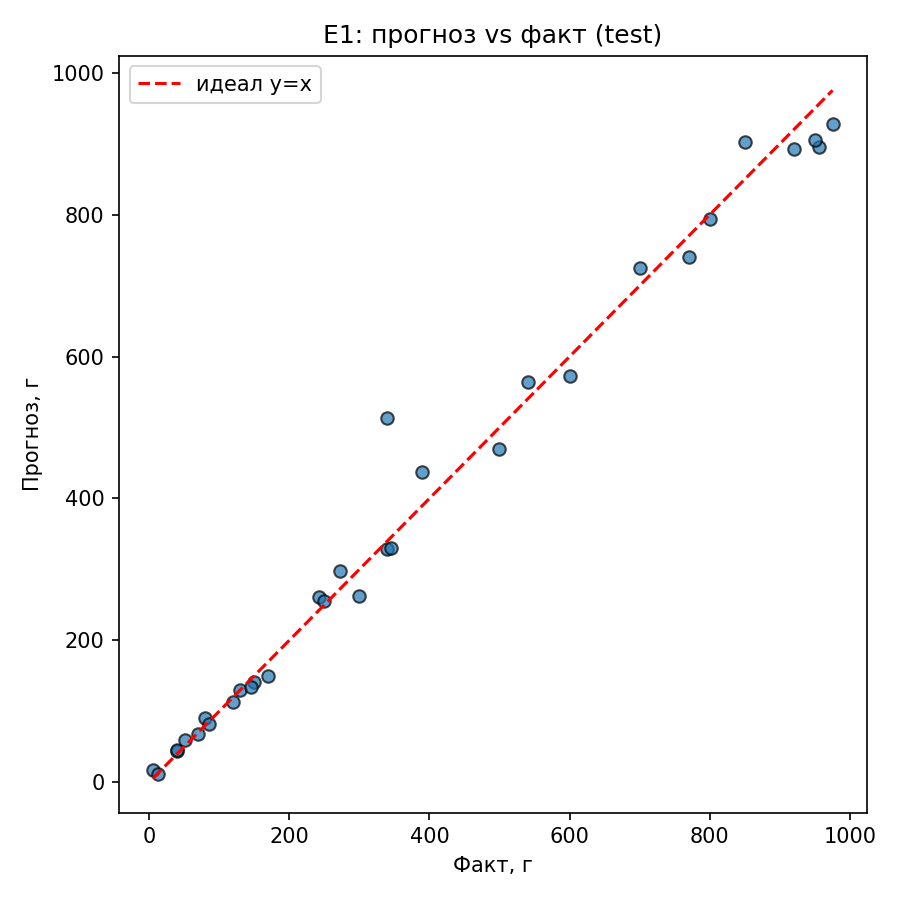


E1_residuals.png


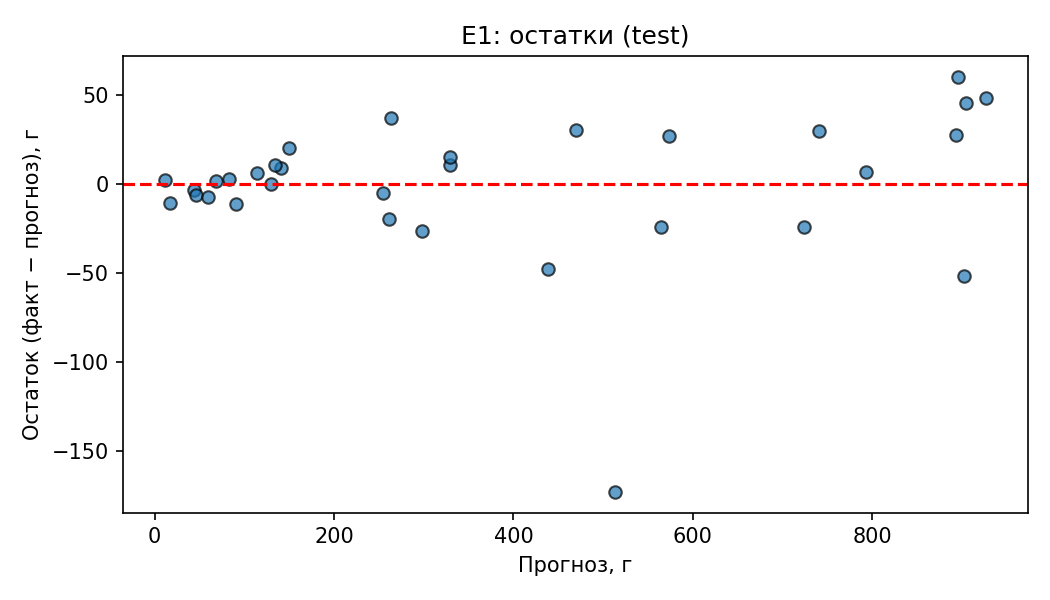


06_bootstrap_ci.png


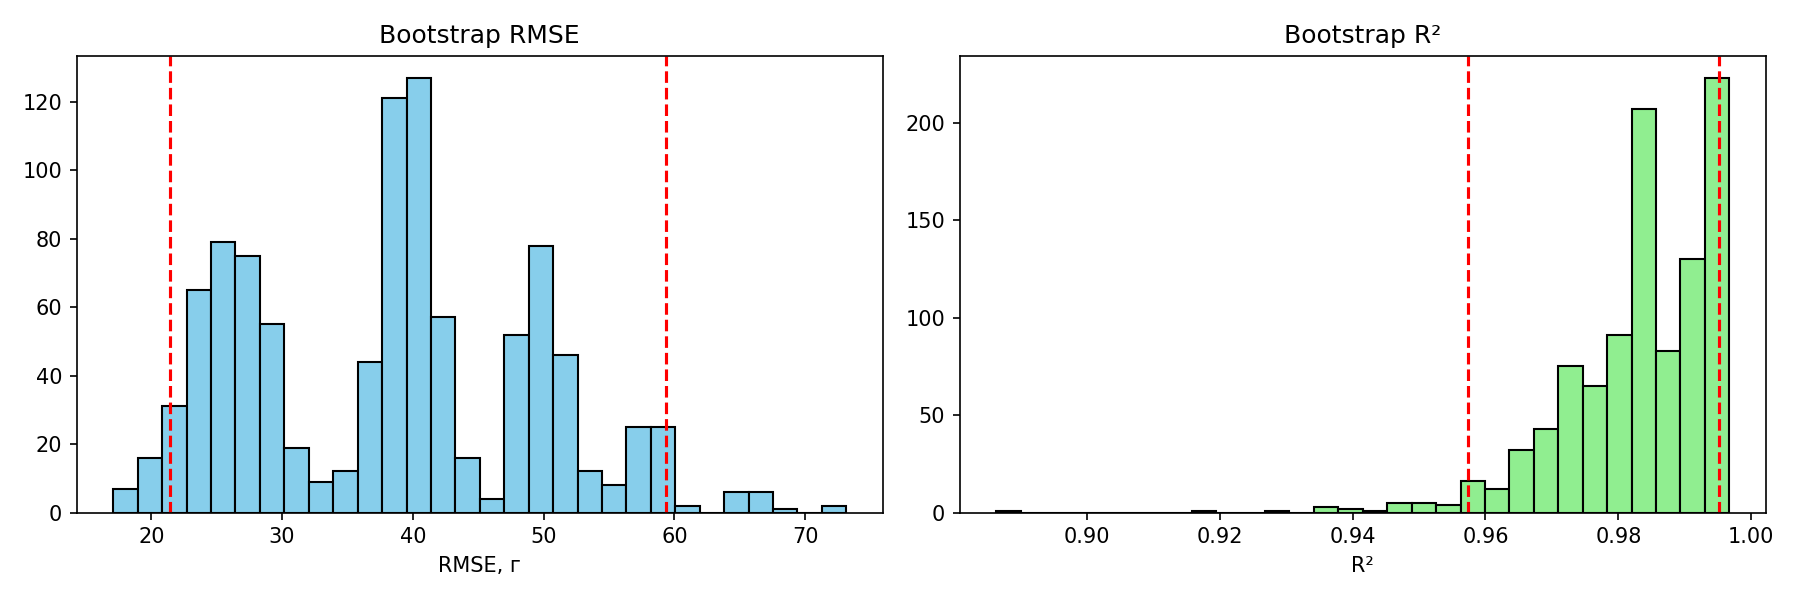

In [45]:
fig_dir = Path("reports/figures")
for name in [
    f"{best_id}_pred_vs_fact.png",
    f"{best_id}_residuals.png",
    "06_bootstrap_ci.png",
]:
    p = fig_dir / name
    if p.exists():
        print(f"\n{name}")
        display(Image(filename=str(p)))

Графики моделей

Прогноз vs факт (test) — все модели E0–E4

E0 — naive_baseline_mean


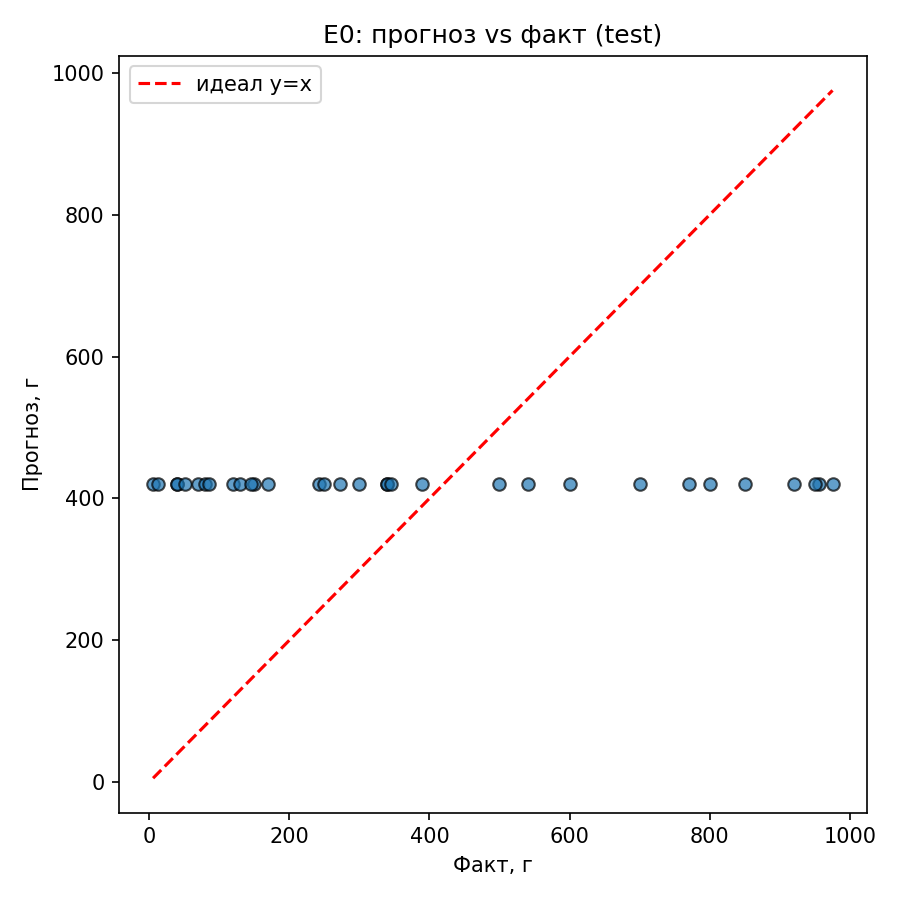


E1 — linear_regression_log_target


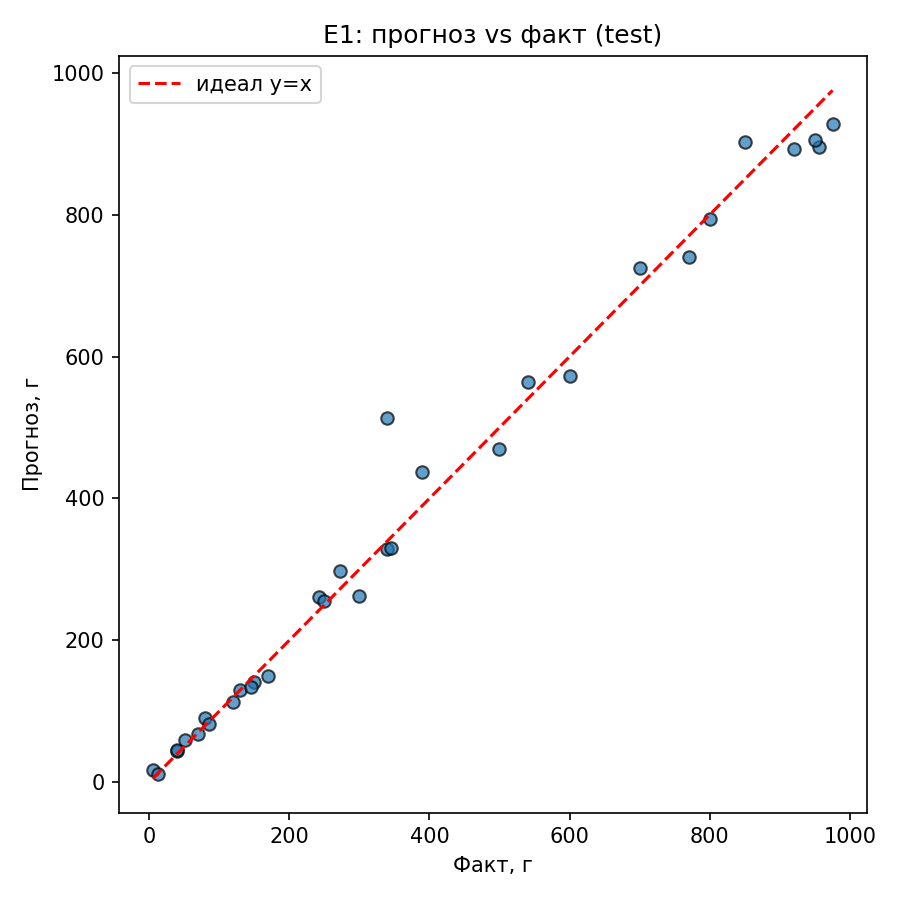


E2 — ridge_regression_cv


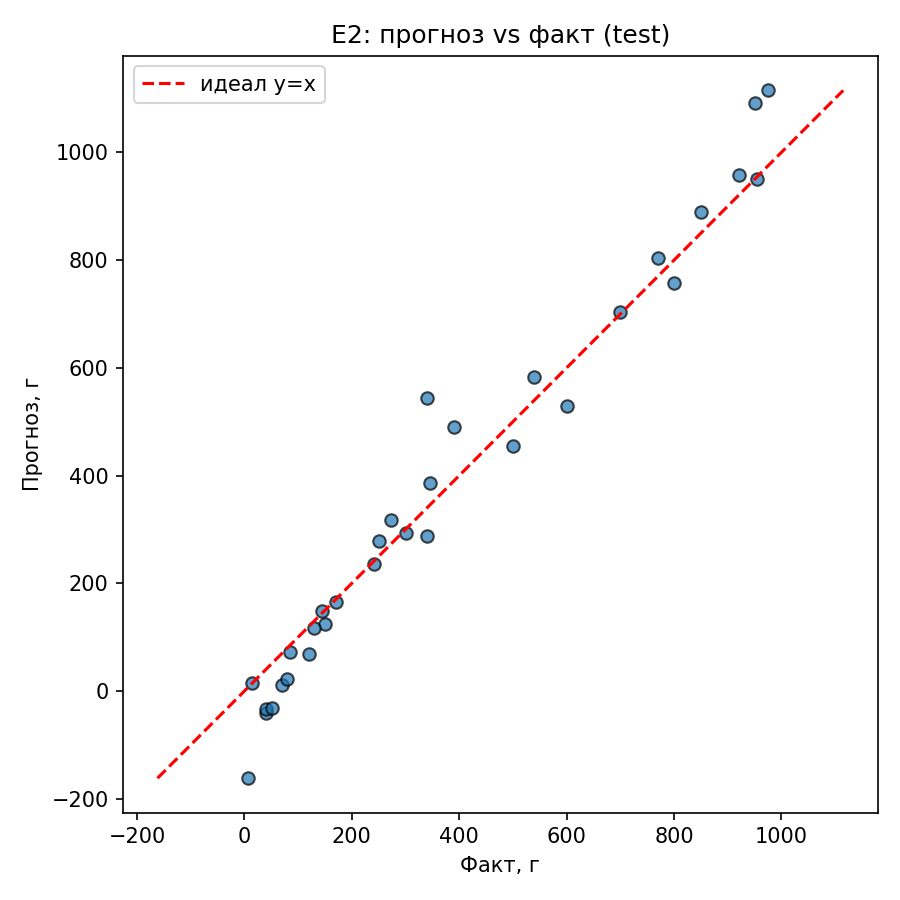


E3 — random_forest


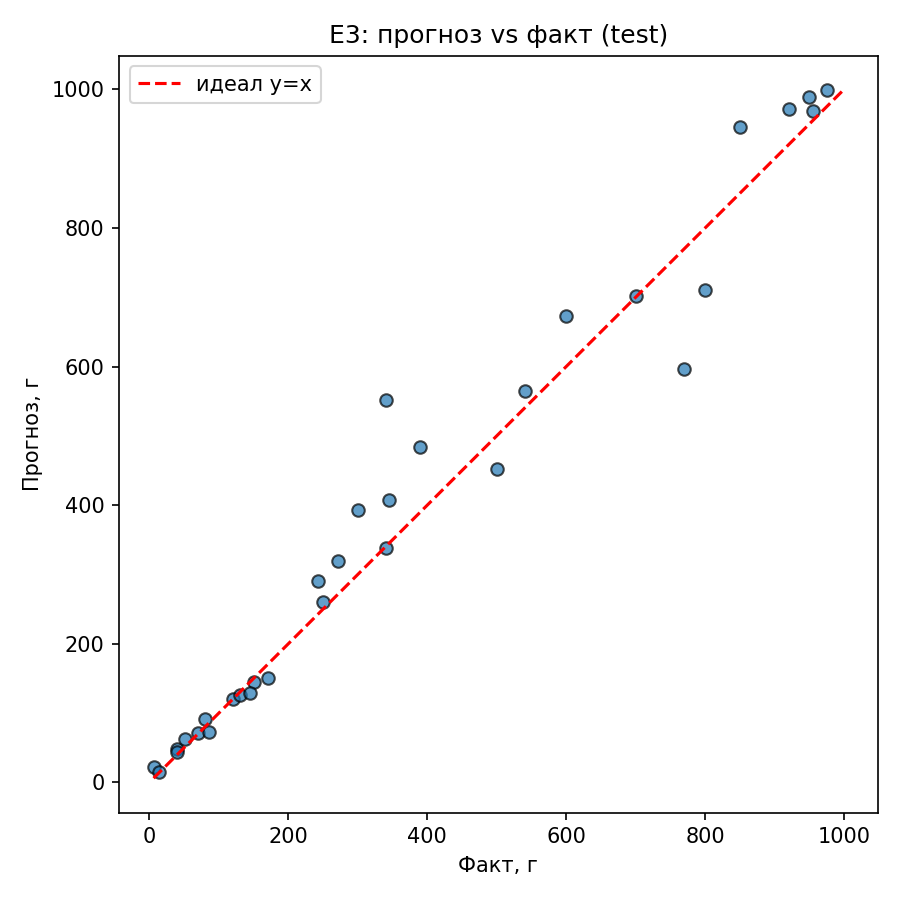


E4 — linear_regression_no_species


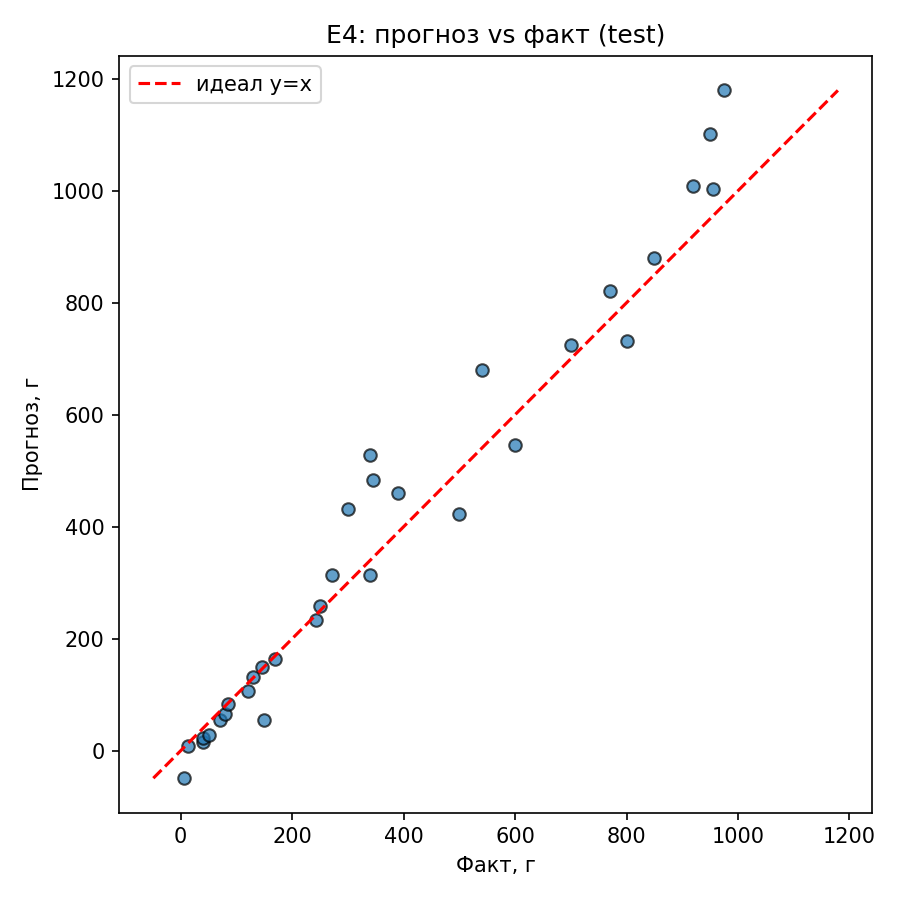


Остатки (test) — все модели E0–E4

E0 — naive_baseline_mean


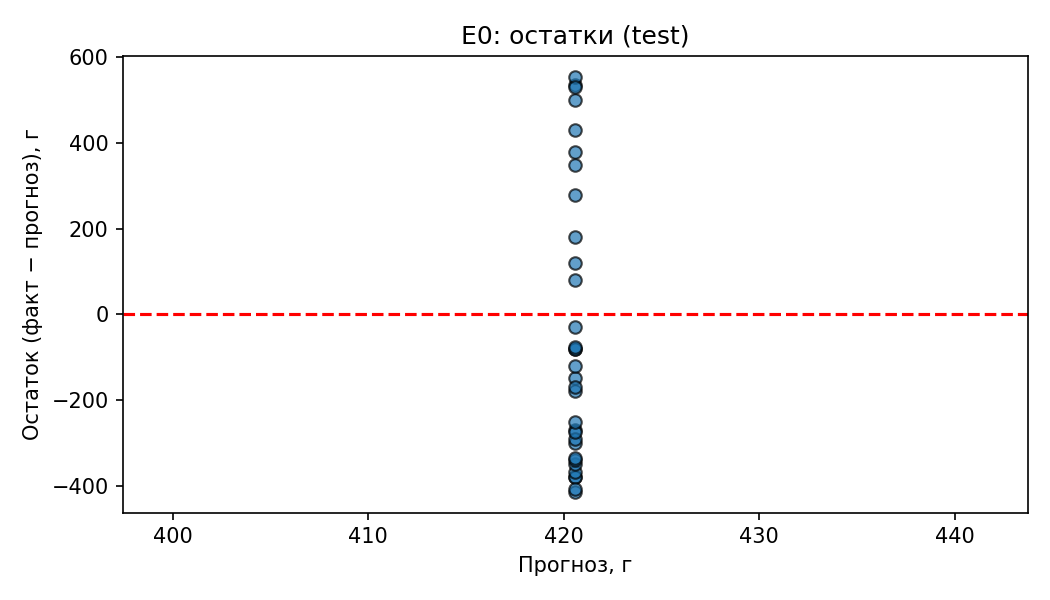


E1 — linear_regression_log_target


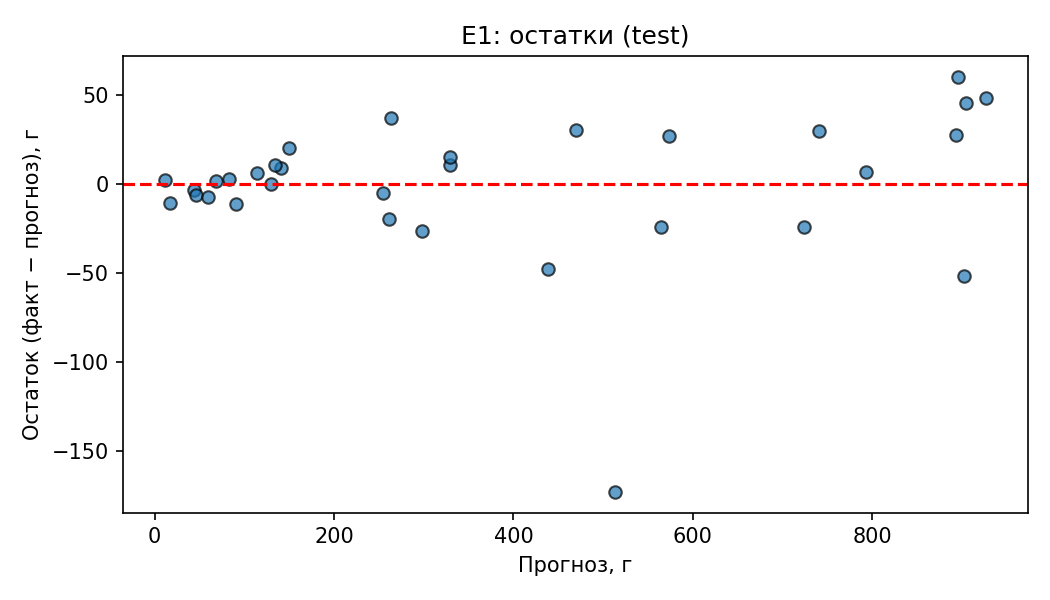


E2 — ridge_regression_cv


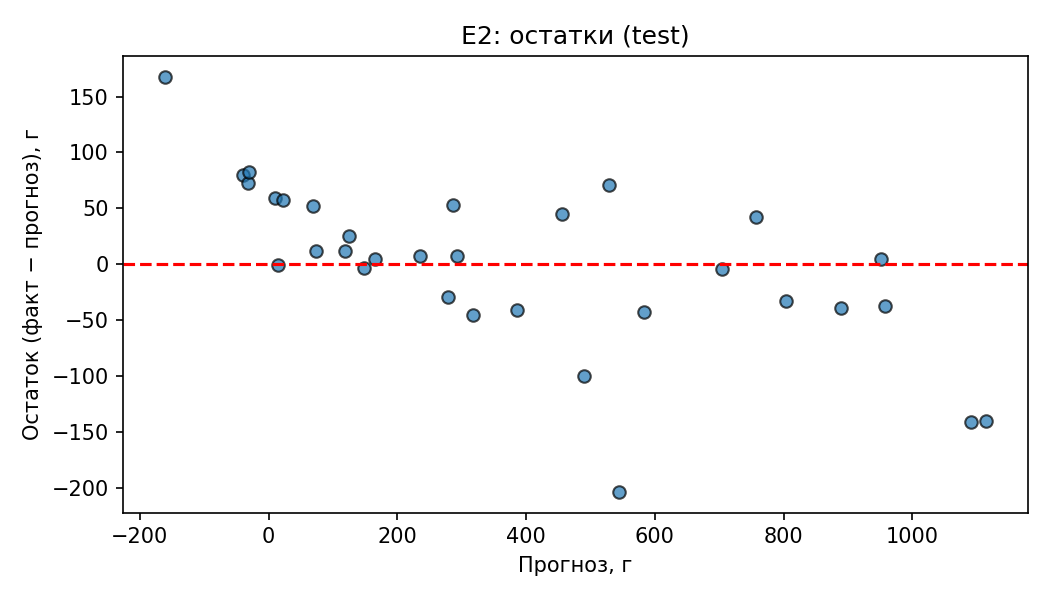


E3 — random_forest


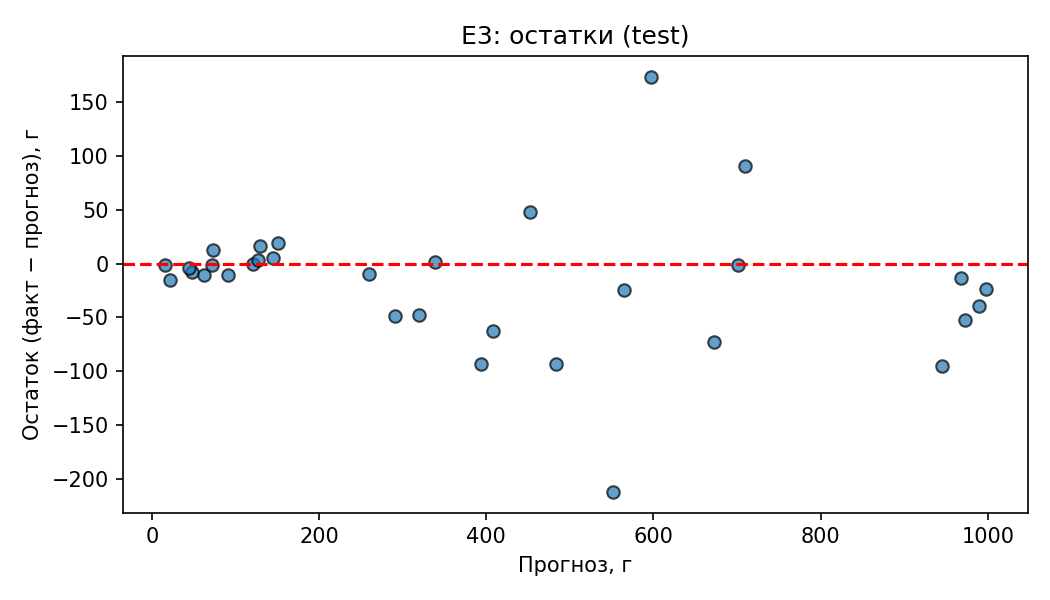


E4 — linear_regression_no_species


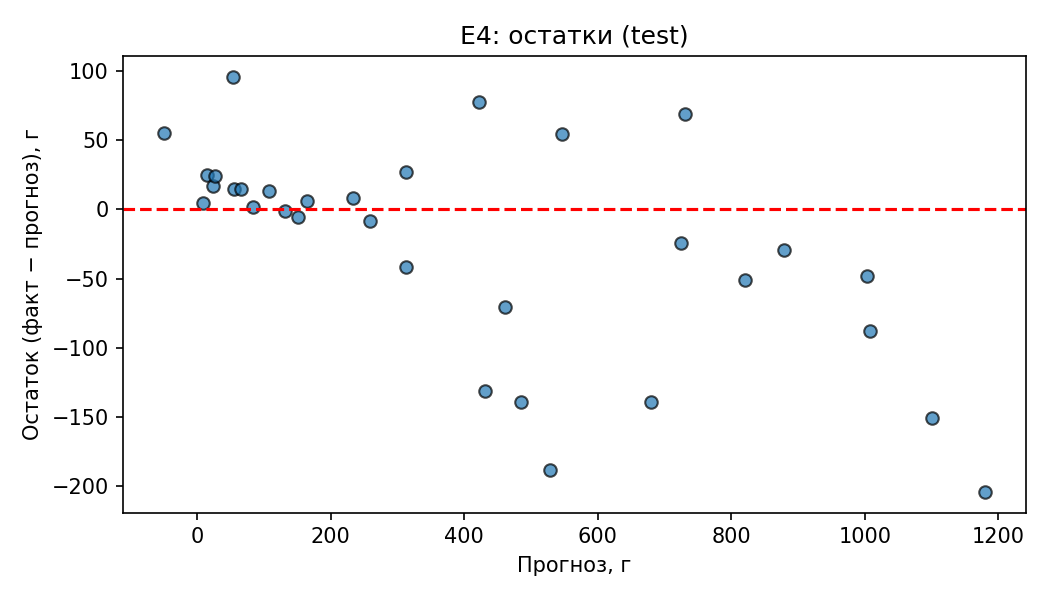


Bootstrap 95% CI (N=1000)


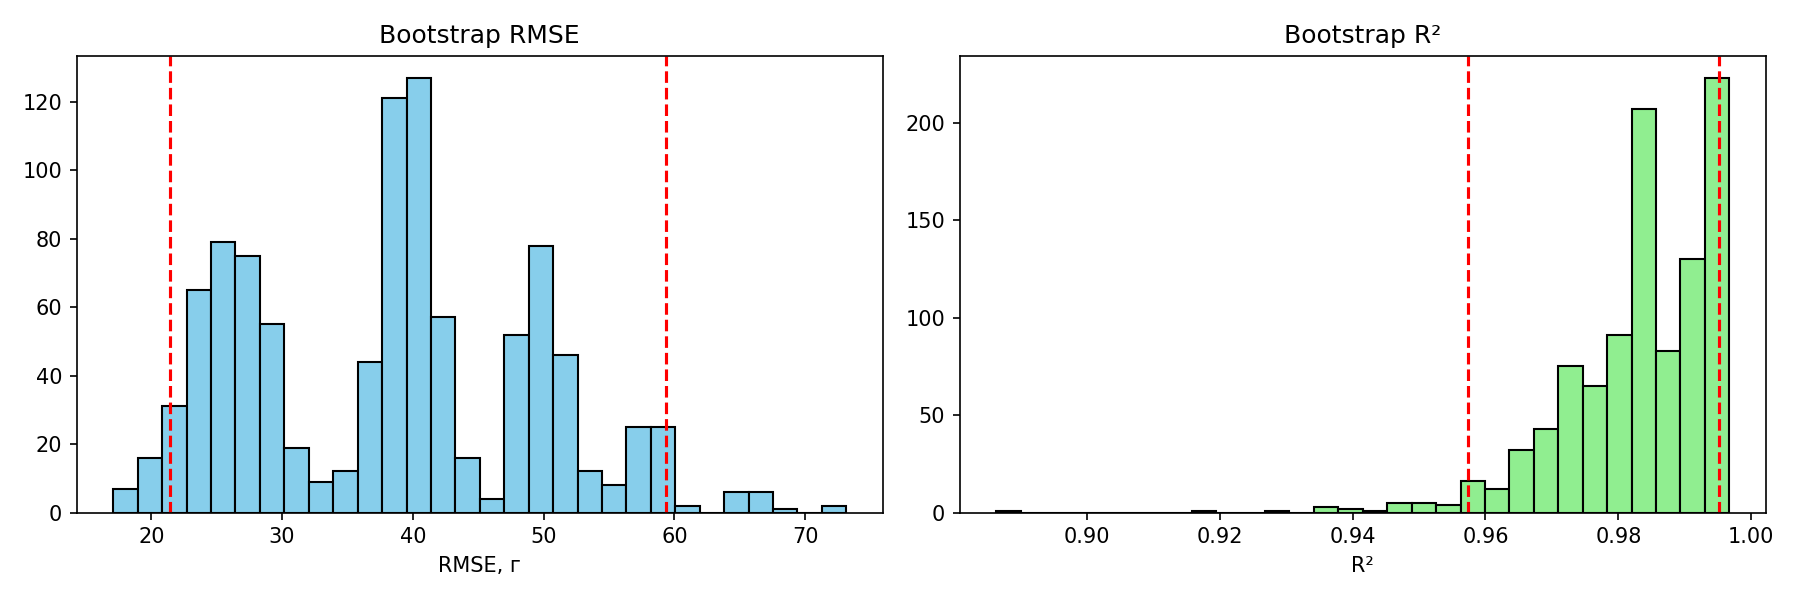

In [46]:
fig_dir = Path("reports/figures")

# Прогноз vs факт для каждой модели E0–E4
print("=" * 60)
print("Прогноз vs факт (test) — все модели E0–E4")
print("=" * 60)
for exp_id in ["E0", "E1", "E2", "E3", "E4"]:
    p = fig_dir / f"{exp_id}_pred_vs_fact.png"
    if p.exists():
        print(f"\n{exp_id} — {metrics[exp_id]['name']}")
        display(Image(filename=str(p)))
    else:
        print(f"\n{exp_id}: файл {p.name} не найден (запустите python -m src.train)")

# Остатки для каждой модели E0–E4
print("\n" + "=" * 60)
print("Остатки (test) — все модели E0–E4")
print("=" * 60)
for exp_id in ["E0", "E1", "E2", "E3", "E4"]:
    p = fig_dir / f"{exp_id}_residuals.png"
    if p.exists():
        print(f"\n{exp_id} — {metrics[exp_id]['name']}")
        display(Image(filename=str(p)))
    else:
        print(f"\n{exp_id}: файл {p.name} не найден (запустите python -m src.train)")

# Bootstrap CI
p = fig_dir / "06_bootstrap_ci.png"
if p.exists():
    print("\n" + "=" * 60)
    print("Bootstrap 95% CI (N=1000)")
    print("=" * 60)
    display(Image(filename=str(p)))
else:
    print("\n06_bootstrap_ci.png не найден (запустите python -m src.bootstrap_ci)")

## Выводы

- **Лучшая модель — E1** (LinearRegression + `log1p`): Test MSE = 1593.63,
  Test R² = 0.9844, Test MAE = 24.98 г.
- **Логарифмирование таргета** дало основной прирост: MSE в 3.3 раза ниже,
  чем у Ridge без `log-target` (E2: 5324.41).
- **Вклад `Species`** подтверждён: E4 (без вида) даёт MSE = 6426.56, R² = 0.9371.
- **Bootstrap 95% CI:** RMSE [21.45; 59.33] г, R² [0.9573; 0.9952] — модель стабильна.
- **Ошибки** сосредоточены на аномальных Bream среднего размера
  (топ-1: 340 → 513 г) — ограничение данных.
- Подробности: `reports/lab02-report.md`, `models/model-card.md`.